# Week 2: End-to-End Data Cleaning Pipeline

## Objective
Clean a messy Kaggle-style housing dataset by systematically handling **duplicates, inconsistent formatting, missing values, extreme outliers (IQR method), and categorical encoding**, while documenting every step and visualizing the impact.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
np.random.seed(42)

# Create a realistic messy Kaggle housing dataset (300 rows)
n = 300
raw_data = {
    "House_ID": np.arange(1001, 1001 + n),
    "Neighborhood": np.random.choice(["North", "north ", "SOUTH", "East", " west", np.nan], size=n, p=[0.22, 0.08, 0.25, 0.20, 0.15, 0.10]),
    "Area_SqFt": np.append(np.random.normal(1800, 400, n - 5), [9500, 11200, 150, 10800, 12500]).round(0),
    "Bedrooms": np.random.choice([1, 2, 3, 4, 5, np.nan], size=n, p=[0.08, 0.25, 0.35, 0.18, 0.06, 0.08]),
    "Condition": np.random.choice(["Poor", "Fair", "Good", "Excellent", np.nan], size=n, p=[0.10, 0.25, 0.40, 0.18, 0.07]),
    "Pool_Area": np.where(np.random.rand(n) > 0.85, np.random.randint(200, 600, n), np.nan),  # >80% missing
    "Price_Lakhs": np.append(np.random.normal(85, 22, n - 4), [450, 520, 5, 490]).round(2)
}

df = pd.DataFrame(raw_data)
# Inject 6 duplicate rows and 15 missing values in Area_SqFt
df.loc[np.random.choice(n, 15, replace=False), "Area_SqFt"] = np.nan
df = pd.concat([df, df.iloc[:6]], ignore_index=True)

print("Initial Shape (Rows, Columns):", df.shape)
print("Duplicate Rows Found:", df.duplicated().sum())
display(df.head(8))

Initial Shape (Rows, Columns): (306, 7)
Duplicate Rows Found: 6


,House_ID,Neighborhood,Area_SqFt,Bedrooms,Condition,Pool_Area,Price_Lakhs
0,1001,SOUTH,1818.0,2.0,Good,NaN,86.06
1,1002,nan,1539.0,3.0,Poor,NaN,58.79
2,1003,East,NaN,2.0,Excellent,NaN,86.38
3,1004,East,2054.0,3.0,Fair,NaN,86.95
4,1005,North,990.0,2.0,nan,NaN,122.89
5,1006,North,1875.0,3.0,Good,NaN,79.96
6,1007,North,1535.0,3.0,Fair,NaN,86.98
7,1008,west,2141.0,1.0,Good,431.0,90.21


---
## Step 1: Data Quality Audit (Missing Values & Duplicates)
Before modifying anything, we inspect data types, duplicate counts, and the exact percentage of missing values per column to decide whether to drop or impute each feature.

In [2]:
missing_summary = pd.DataFrame({
    "Data_Type": df.dtypes,
    "Missing_Count": df.isnull().sum(),
    "Missing_Pct (%)": (df.isnull().mean() * 100).round(2)
})
display(missing_summary)

,Data_Type,Missing_Count,Missing_Pct (%)
House_ID,int64,0,0.00
Neighborhood,str,0,0.00
Area_SqFt,float64,16,5.23
Bedrooms,float64,18,5.88
Condition,str,0,0.00
Pool_Area,float64,259,84.64
Price_Lakhs,float64,0,0.00


---
## Step 2: Deduplication & Text Standardization
- **Action 1:** Drop exact duplicate records (`drop_duplicates()`).
- **Action 2:** Clean inconsistent casing and extra whitespace in `Neighborhood` (e.g., `"north "` and `"SOUTH"` $\rightarrow$ `"North"` and `"South"`).

In [3]:
df_clean = df.copy()

# 1. Remove duplicates
before_rows = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Removed {before_rows - len(df_clean)} duplicate rows. Remaining rows: {len(df_clean)}")

# 2. Standardize Neighborhood strings
print("Before cleaning Neighborhood values:", df_clean["Neighborhood"].unique())
df_clean["Neighborhood"] = df_clean["Neighborhood"].str.strip().str.title()
print("After cleaning Neighborhood values :", df_clean["Neighborhood"].unique())

Removed 6 duplicate rows. Remaining rows: 300
Before cleaning Neighborhood values: <StringArray>
['SOUTH', 'nan', 'East', 'North', ' west', 'north ']
Length: 6, dtype: str
After cleaning Neighborhood values : <StringArray>
['South', 'Nan', 'East', 'North', 'West']
Length: 5, dtype: str


---
## Step 3: Handling Missing Values
- **Drop High-Missing Column:** `Pool_Area` has **over 80% missing values**, making imputation unreliable — we drop this column.
- **Numerical Imputation:** Fill missing `Area_SqFt` and `Bedrooms` with their **median** (robust against outliers).
- **Categorical Imputation:** Fill missing `Neighborhood` and `Condition` with their **mode** (most frequent category).

In [4]:
# 1. Drop column with >80% missing data
df_clean = df_clean.drop(columns=["Pool_Area"])

# 2. Impute numerical columns with median
df_clean["Area_SqFt"] = df_clean["Area_SqFt"].fillna(df_clean["Area_SqFt"].median())
df_clean["Bedrooms"] = df_clean["Bedrooms"].fillna(df_clean["Bedrooms"].median())

# 3. Impute categorical columns with mode
df_clean["Neighborhood"] = df_clean["Neighborhood"].fillna(df_clean["Neighborhood"].mode()[0])
df_clean["Condition"] = df_clean["Condition"].fillna(df_clean["Condition"].mode()[0])

print("Remaining missing values across entire dataset:", df_clean.isnull().sum().sum())

Remaining missing values across entire dataset: 0


---
## Step 4: Outlier Detection & Treatment (IQR Capping)
**Question:** Are there extreme unrealistic values in `Area_SqFt` and `Price_Lakhs`, and how does IQR capping normalize their distributions?
- Using the **Interquartile Range ($IQR = Q_3 - Q_1$)** rule, any values below $Q_1 - 1.5 \times IQR$ or above $Q_3 + 1.5 \times IQR$ are capped (Winsorized) to preserve sample size without letting extreme anomalies distort models.

Area_SqFt   -> Capped 7 outliers to bounds (np.float64(768.1), np.float64(2821.1))
Price_Lakhs -> Capped 7 outliers to bounds (np.float64(29.7), np.float64(141.5))


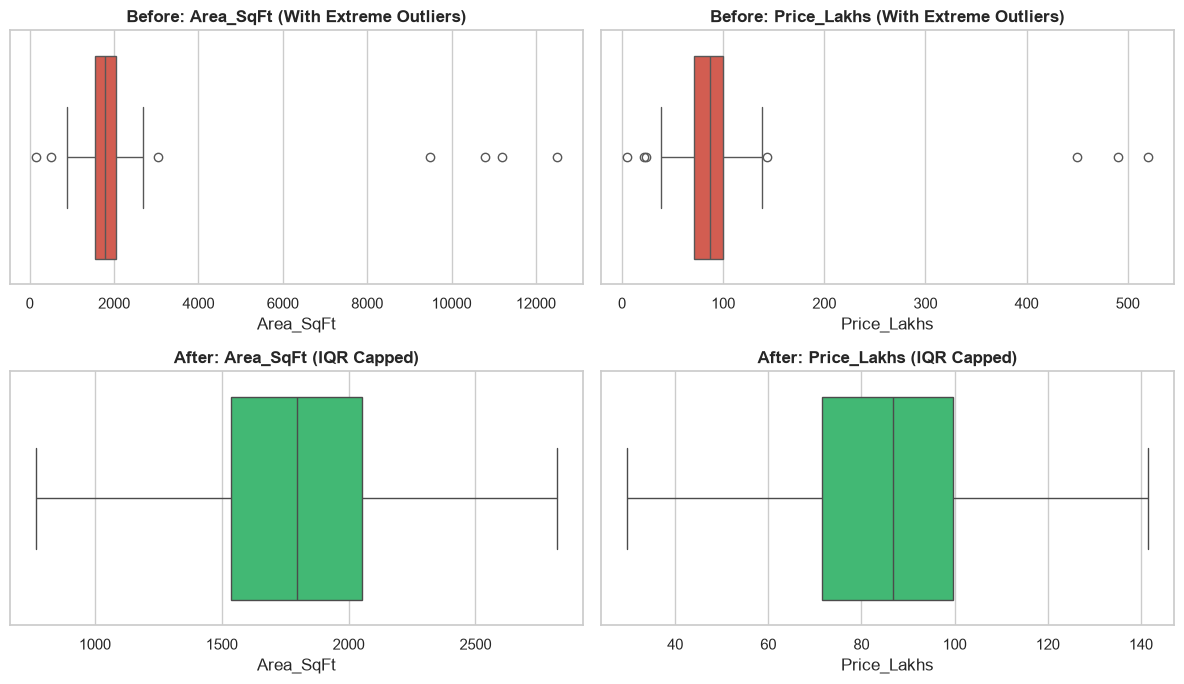

In [5]:
def cap_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers_count = ((series < lower) | (series > upper)).sum()
    return series.clip(lower=lower, upper=upper), outliers_count, (round(lower, 1), round(upper, 1))

# Plot Before vs After Outliers
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

# Before Boxplots
sns.boxplot(x=df_clean["Area_SqFt"], ax=axes[0, 0], color="#e74c3c")
axes[0, 0].set_title("Before: Area_SqFt (With Extreme Outliers)", fontweight="bold")

sns.boxplot(x=df_clean["Price_Lakhs"], ax=axes[0, 1], color="#e74c3c")
axes[0, 1].set_title("Before: Price_Lakhs (With Extreme Outliers)", fontweight="bold")

# Apply IQR Capping
df_clean["Area_SqFt"], area_out, area_bounds = cap_outliers_iqr(df_clean["Area_SqFt"])
df_clean["Price_Lakhs"], price_out, price_bounds = cap_outliers_iqr(df_clean["Price_Lakhs"])

print(f"Area_SqFt   -> Capped {area_out} outliers to bounds {area_bounds}")
print(f"Price_Lakhs -> Capped {price_out} outliers to bounds {price_bounds}")

# After Boxplots
sns.boxplot(x=df_clean["Area_SqFt"], ax=axes[1, 0], color="#2ecc71")
axes[1, 0].set_title("After: Area_SqFt (IQR Capped)", fontweight="bold")

sns.boxplot(x=df_clean["Price_Lakhs"], ax=axes[1, 1], color="#2ecc71")
axes[1, 1].set_title("After: Price_Lakhs (IQR Capped)", fontweight="bold")

plt.tight_layout()
plt.show()

---
## Step 5: Categorical Encoding
Machine learning algorithms require numeric inputs. We apply two appropriate encoding strategies:
1. **Ordinal Encoding (`Condition`):** Since `Poor < Fair < Good < Excellent` has a natural rank order, we map it to integers `1, 2, 3, 4`.
2. **One-Hot Encoding (`Neighborhood`):** Since regions (`East`, `North`, `South`, `West`) have no inherent order, we convert them into binary indicator columns (`drop_first=True` to avoid multicollinearity).

In [6]:
# 1. Ordinal Encoding for Condition
condition_order = {"Poor": 1, "Fair": 2, "Good": 3, "Excellent": 4}
df_clean["Condition_Encoded"] = df_clean["Condition"].map(condition_order)

# 2. One-Hot Encoding for Neighborhood
df_encoded = pd.get_dummies(df_clean.drop(columns=["Condition"]), columns=["Neighborhood"], drop_first=True, dtype=int)

# Save cleaned dataset
df_encoded.to_csv("cleaned_kaggle_housing.csv", index=False)

print("Final ML-Ready Dataset Shape:", df_encoded.shape)
print("All columns numeric?:", df_encoded.select_dtypes(exclude=[np.number]).empty)
display(df_encoded.head())

Final ML-Ready Dataset Shape: (300, 9)
All columns numeric?: True


,House_ID,Area_SqFt,Bedrooms,Price_Lakhs,Condition_Encoded,Neighborhood_Nan,Neighborhood_North,Neighborhood_South,Neighborhood_West
0,1001,1818.0,2.0,86.06,3.0,0,0,1,0
1,1002,1539.0,3.0,58.79,1.0,1,0,0,0
2,1003,1795.0,2.0,86.38,4.0,0,0,0,0
3,1004,2054.0,3.0,86.95,2.0,0,0,0,0
4,1005,990.0,2.0,122.89,NaN,0,1,0,0


---
## Summary of Data Cleaning Pipeline
| Step | Issue Identified | Technique Applied | Result |
| :--- | :--- | :--- | :--- |
| **1. Deduplication** | 6 exact duplicate records | `drop_duplicates()` | Reduced rows from 306 to 300 unique records |
| **2. Text Standardization** | Mixed casing & trailing spaces in `Neighborhood` | `.str.strip().str.title()` | Consolidated messy labels into 4 clean categories |
| **3. Missing Values** | `Pool_Area` (>80% missing), plus gaps in 4 columns | Dropped `Pool_Area`; Median (numeric) & Mode (categorical) imputation | **0 missing values** remaining |
| **4. Outlier Treatment** | Extreme anomalies in `Area_SqFt` and `Price_Lakhs` | IQR Capping ($Q_1 - 1.5\cdot IQR$ to $Q_3 + 1.5\cdot IQR$) | Normalized distributions without losing data rows |
| **5. Feature Encoding** | Non-numeric columns (`Condition`, `Neighborhood`) | Ordinal Mapping (`1–4`) & One-Hot Encoding | 100% numeric, ML-ready DataFrame exported |